<div style="background: linear-gradient(135deg, #4a0f24 0%, #8e2a4f 100%); color: #ffffff; text-align: center; padding: 50px 30px; border-radius: 14px; box-shadow: 0 6px 18px rgba(0,0,0,0.25); margin: 10px auto; max-width: 900px;">

<div style="font-size: 0.9em; letter-spacing: 4px; text-transform: uppercase; opacity: 0.8; margin-bottom: 12px;">Projet . Machine Learning 1</div>

<div style="font-size: 2.6em; font-weight: 700; line-height: 1.15; margin-bottom: 14px;"> 🍷 Classification de la qualité du vin</div>

<div style="width: 80px; height: 3px; background: #ffffff; opacity: 0.6; margin: 0 auto 22px auto; border-radius: 2px;"></div>

<div style="font-size: 1.25em; font-weight: 600;">Mohamed Amine Rahmouni</div>

<div style="font-size: 0.95em; opacity: 0.8; margin-top: 6px;">EFREI · 2026-2027 · Octobre 2026</div>

</div>

## 📌 Présentation
L'objectif est de prédire si un vin est **« bon »** (note ≥ 7) à partir de 11 mesures physico-chimiques, par classification supervisée. Les données sont le jeu *Wine Quality* de l'UCI (Cortez et al., 2009) : vins rouges et blancs du Vinho Verde, soit 6497 observations (5320 après suppression des doublons).

## 🧹 Préparation des données
- Fusion des vins rouges et blancs, ajout de la variable `type` (encodée en `type_white`).
- Suppression de 1177 doublons pour éviter la fuite de données entre entraînement et test.
- Aucune valeur manquante ; valeurs extrêmes conservées (plausibles chimiquement).
- Cible binaire : `quality ≥ 7`. **Classes déséquilibrées : 19 % de bons vins.**
- Découpage 80/20 stratifié (4256 observations d'entraînement, 1064 de test) ; standardisation et sélection de variables placées **dans un Pipeline** pour éviter toute fuite.
- Sélection de variables : filtre de Pearson (seuil 0,03, qui n'écarte que `free sulfur dioxide`) pour les modèles de base, et `SelectKBest` (k optimisé par validation croisée) pour les modèles optimisés.

## 🤖 Méthode
Les **cinq modèles demandés** sont comparés : régression logistique, k-NN, arbre de décision, Naive Bayes, SVM (noyau RBF). Deux **modèles complémentaires** non linéaires (Random Forest et Gradient Boosting) sont ajoutés pour vérifier si les modèles imposés atteignent un plafond. Hyperparamètres optimisés par **Grid Search** et **Random Search** avec validation croisée stratifiée à 5 plis, critère **F1**. Les trois meilleurs modèles sont ensuite comparés par validation croisée répétée (5×5).

## 📈 Résultats (jeu de test, modèles optimisés)

| Modèle | Précision | Rappel | F1 | AUC | F1 en validation croisée | Écart F1 train-test |
|---|---|---|---|---|---|---|
| Régression logistique | 0,400 | 0,797 | 0,533 | 0,817 | 0,539 ± 0,020 | 0,007 |
| k-NN | **0,628** | 0,460 | 0,531 | 0,824 | 0,492 ± 0,023 | 0,469 |
| Arbre de décision | 0,366 | 0,733 | 0,488 | 0,784 | 0,515 ± 0,018 | 0,037 |
| Naive Bayes | 0,381 | 0,584 | 0,461 | 0,761 | 0,500 ± 0,011 | 0,037 |
| **SVM (RBF)** | 0,405 | **0,827** | 0,544 | 0,854 | 0,546 ± 0,011 | 0,041 |
| Random Forest *(complément)* | 0,561 | 0,634 | **0,595** | **0,872** | **0,562 ± 0,025** | 0,268 |
| Gradient Boosting *(complément)* | 0,476 | 0,777 | 0,590 | 0,867 | 0,551 ± 0,014 | 0,121 |

**Modèle retenu : SVM (noyau RBF).** Trois modèles ont des performances statistiquement indiscernables : SVM, Gradient Boosting et Random Forest (F1 en validation croisée répétée 5×5 : 0,546 ± 0,014, 0,550 ± 0,018 et 0,555 ± 0,026 ; aucun n'est meilleur que les autres dans plus de 68 % des plis). Nous les départageons selon le compromis biais/variance : le SVM a la variance la plus faible, le plus petit écart entre entraînement et test (0,04 contre 0,12 pour le boosting et 0,27 pour la forêt) et le meilleur rappel (0,83), pour un modèle moins complexe. L'avantage des modèles d'ensemble sur le jeu de test (F1 de 0,59 contre 0,54) n'est pas confirmé par la validation croisée : avec environ 200 bons vins dans le test, il est probablement en grande partie dû à la composition de cet échantillon.

## 🔍 Observations clés
- L'accuracy est trompeuse : le k-NN atteint 0,846 mais ne retrouve que 46 % des bons vins.
- Le k-NN surapprend fortement (F1 train 1,000 contre 0,531 en test), et le Random Forest aussi, dans une moindre mesure (0,863 contre 0,595).
- Les modèles d'ensemble (Random Forest, Gradient Boosting) font un peu mieux sur le jeu de test, mais pas de façon significative en validation croisée répétée.
- Les variables les plus liées à la qualité sont l'alcool, la densité, les chlorures et l'acidité volatile.
- La standardisation est déterminante : F1 du SVM de 0,416 à 0,545, du k-NN de 0,281 à 0,477.
- Le filtre de Pearson apporte peu : les meilleurs modèles gardent 11 à 12 variables avec `SelectKBest`.

## ⚠️ Obstacles rencontrés
- Fort déséquilibre des classes, géré par stratification, pondération des classes et choix du F1.
- Risque de fuite de données avec la standardisation hors validation croisée, corrigé en utilisant un Pipeline.
- Compromis précision/rappel difficile : les modèles les plus sensibles (SVM, régression logistique) retrouvent environ 80 % des bons vins mais avec une précision d'environ 0,40, tandis que le k-NN est plus précis (0,63) mais manque la moitié des bons vins. Le signal contenu dans les variables physico-chimiques est faible.

## ▶️ Lancer le projet
```bash
git clone <URL-du-dépôt>
cd <nom-du-dépôt>
python -m venv venv
source venv/bin/activate        # Windows : venv\Scripts\activate
pip install -r requirements.txt
jupyter notebook projet_vin.ipynb
```

## ✅ Tests
```bash
python -m pytest -v tests/                          # tests unitaires
python -m pytest --nbmake projet_vin.ipynb          # exécute le notebook en entier
```

## 📁 Structure du dépôt
```
├── projet_vin.ipynb        # notebook principal
├── wine.py                 # fonctions réutilisables (préparation, split, pipeline)
├── tests/test_wine.py      # tests unitaires
├── winequality-red.csv     # données (UCI)
├── winequality-white.csv
├── requirements.txt
├── pytest.ini
└── README.md
```

## 📚 Outils
Python 3.9, pandas, NumPy, scikit-learn, SciPy, Matplotlib, Seaborn, pytest, nbmake. Données : UCI Machine Learning Repository.

## Mini-glossaire

### Les bases

| Terme | Explication simple |
|---|---|
| **Variable explicative** (*feature*) | Une mesure qui sert à prédire (ex. le taux d'alcool). |
| **Cible** (*target*) | Ce qu'on veut prédire : ici « bon vin » (1) ou non (0). |
| **Jeu d'entraînement** | Les exemples avec lesquels le modèle apprend (80 %). |
| **Jeu de test** | Des exemples mis de côté, utilisés **une seule fois** à la fin pour vérifier que le modèle sait généraliser (20 %). |
| **Surapprentissage** | Le modèle apprend les exemples « par cœur » (y compris leur bruit) et se trompe sur de nouveaux vins. |
| **Fuite de données** | Une information du jeu de test « s'infiltre » dans l'entraînement, ce qui rend les scores trop beaux pour être vrais. |
| **Classes déséquilibrées** | Une catégorie est beaucoup plus rare que l'autre (19 % de bons vins contre 81 %). |
| **Valeur aberrante** (*outlier*) | Une mesure très éloignée des autres (ex. un vin à 65 g/L de sucre). Ici, elles sont conservées car plausibles. |
| **Corrélation de Pearson** | Un nombre entre −1 et 1 qui mesure le lien **linéaire** entre deux variables. Elle ne détecte pas les relations non linéaires. |

### Préparation et réglage

| Terme | Explication simple |
|---|---|
| **Standardisation** | Mettre toutes les variables à la même échelle (moyenne 0, écart-type 1). |
| **Pipeline** | Une chaîne d'étapes (standardiser, sélectionner, prédire) appliquée de façon identique et sans fuite. |
| **Sélection de variables** | Ne garder que les variables utiles pour réduire le bruit. Ici : un filtre sur la corrélation, puis `SelectKBest` (garde les *k* meilleures variables). |
| **Paramètre / hyperparamètre** | Un *paramètre* est appris par le modèle (ex. un coefficient). Un *hyperparamètre* est un réglage choisi avant l'apprentissage (ex. le nombre de voisins $k$). |
| **Validation croisée** | On découpe l'entraînement en 5 parties, on s'entraîne sur 4 et on teste sur la 5e, en tournant. *Stratifiée* : chaque partie garde la même proportion de bons vins. |
| **Grid Search** | On teste **toutes** les combinaisons d'hyperparamètres d'une grille. Exhaustif mais coûteux. |
| **Random Search** | On teste des combinaisons **tirées au hasard**. Plus rapide, et souvent presque aussi bon. |
| **Pondération des classes** (`class_weight`) | Une erreur sur un bon vin (rare) compte plus qu'une erreur sur un vin ordinaire, pour compenser le déséquilibre. |
| **Modèle d'ensemble** | Un modèle qui combine plusieurs arbres (Random Forest, Gradient Boosting), souvent plus puissant mais plus complexe. |

### Évaluation

| Terme | Explication simple |
|---|---|
| **Accuracy** | Part de prédictions correctes. Trompeuse ici : dire « jamais bon » donnerait déjà 81 %. |
| **Précision** | Parmi les vins annoncés « bons », la part qui l'est vraiment. |
| **Rappel** | Parmi les vrais bons vins, la part que le modèle retrouve. |
| **F1** | Moyenne harmonique de la précision et du rappel : elle est basse dès que l'un des deux l'est. C'est notre critère principal. |
| **Faux positif / faux négatif** | Un vin ordinaire annoncé « bon » / un bon vin raté. |
| **Matrice de confusion** | Un tableau qui compte les vrais et faux positifs et négatifs. |
| **Courbe ROC et AUC** | La courbe compare les bons vins retrouvés aux faux positifs, selon le seuil. L'AUC la résume : 0,5 = hasard, 1 = parfait. |
| **Seuil de décision** | Le niveau de confiance à partir duquel le modèle dit « bon vin » (0,5 par défaut). Le baisser augmente le rappel mais réduit la précision. |
| **Biais / variance** | Un modèle à **biais** élevé est trop simple et rate la structure des données. Un modèle à **variance** élevée est trop souple et colle au bruit (surapprentissage). On cherche un compromis. |

In [1]:
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)

import pandas as pd, numpy as np, sklearn, matplotlib
import seaborn as sns
import matplotlib.pyplot as plt
print("Tout est OK, sklearn", sklearn.__version__)

Tout est OK, sklearn 1.6.1


### 1. Constitution du jeu de données
**Objectif.** 
Constituer un échantillon unique à partir des deux fichiers de vins (rouge, blanc) du jeu UCI *Wine Quality* (Cortez et al., 2009).
**Méthode.** Lecture des fichiers CSV (séparateur `;`), ajout d'une variable `type`, concaténation. On obtient 6497 observations, 11 variables physico-chimiques continues, la note `quality` (entier de 3 à 9) et `type`.
**Justification.** La fusion augmente la taille de l'échantillon, donc réduit la variance d'estimation des modèles. Conserver `type` permet de tenir compte d'une hétérogénéité connue entre les deux populations.
**Limite.** Les deux types de vin ont des distributions différentes : le modèle apprend une frontière commune, sans modèle spécifique à chaque type.

In [2]:
red = pd.read_csv("winequality-red.csv", sep=";")
white = pd.read_csv("winequality-white.csv", sep=";")

red["type"] = "red"
white["type"] = "white"
df = pd.concat([red, white], ignore_index=True)

print(df.shape)
df.head()

(6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


In [3]:
## **Interprétation :** le dataset contient 6497 vins, 11 variables physicochimiques , continues, la note `quality` et la variable catégorielle `type`.
## Source : UCI Machine Learning Repository (Cortez et al., 2009).

### 2. Contrôle de la qualité des données
**Objectif.** Détecter les valeurs manquantes, les types incohérents et les doublons avant toute modélisation.
**Méthode.** Inspection des types (`info`), comptage des valeurs nulles, des lignes dupliquées et statistiques descriptives (moyenne, écart-type, quartiles, extrema).
**Résultat.** Aucune valeur manquante, donc aucune imputation nécessaire ; 1177 doublons exacts (18,1 %).

In [4]:
# Aperçu des premières lignes ( 5 premiers vins rouges et 5 premiers vins blanc ) 

print("5 premiers vins rouges :")  
display(df[df["type"] == "red"].head())

print("5 premiers vins blancs :")
display(df[df["type"] == "white"].head())

# Informations générales
df.info()

# Valeurs manquantes
print("Valeurs manquantes :")
print(df.isna().sum())

# Doublons
print("Nombre de doublons :", df.duplicated().sum())

# Statistiques descriptives
display(df.describe().T)
print("Dimensions du dataset :", df.shape)


5 premiers vins rouges :


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


5 premiers vins blancs :


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type
1599,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6,white
1600,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6,white
1601,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6,white
1602,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6,white
1603,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6,white


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  type                  6497 non-null   object 
dtypes: float64(11), int64(1), object(1)
memory usage: 660.0+ KB
Valeurs manquantes :
fixed acidity           0
volatile acidity

,count,mean,std,min,25%,50%,75%,max
fixed acidity,6497.0,7.215307,1.296434,3.80000,6.40000,7.00000,7.70000,15.90000
volatile acidity,6497.0,0.339666,0.164636,0.08000,0.23000,0.29000,0.40000,1.58000
citric acid,6497.0,0.318633,0.145318,0.00000,0.25000,0.31000,0.39000,1.66000
residual sugar,6497.0,5.443235,4.757804,0.60000,1.80000,3.00000,8.10000,65.80000
chlorides,6497.0,0.056034,0.035034,0.00900,0.03800,0.04700,0.06500,0.61100
free sulfur dioxide,6497.0,30.525319,17.749400,1.00000,17.00000,29.00000,41.00000,289.00000
total sulfur dioxide,6497.0,115.744574,56.521855,6.00000,77.00000,118.00000,156.00000,440.00000
density,6497.0,0.994697,0.002999,0.98711,0.99234,0.99489,0.99699,1.03898
pH,6497.0,3.218501,0.160787,2.72000,3.11000,3.21000,3.32000,4.01000
sulphates,6497.0,0.531268,0.148806,0.22000,0.43000,0.51000,0.60000,2.00000


Dimensions du dataset : (6497, 13)


### 3. Suppression des doublons
**Justification.** L'erreur de généralisation n'est estimée sans biais que si le jeu de test est indépendant du jeu d'entraînement. Des observations identiques réparties entre les deux ensembles introduisent une **fuite de données** (*data leakage*) et surestiment les performances. La suppression est donc effectuée avant le découpage.
**Compromis.** Des vins distincts peuvent avoir des mesures identiques à cause de l'arrondi : nous acceptons de perdre cette information pour garantir l'intégrité de l'évaluation. Le jeu passe à 5320 observations.

In [5]:
print("Avant :", df.shape)
df = df.drop_duplicates().reset_index(drop=True)
print("Après :", df.shape)

Avant : (6497, 13)
Après : (5320, 13)


In [6]:
df.info()
print("Valeurs manquantes :\n", df.isna().sum())
print("Doublons :", df.duplicated().sum())
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5320 entries, 0 to 5319
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         5320 non-null   float64
 1   volatile acidity      5320 non-null   float64
 2   citric acid           5320 non-null   float64
 3   residual sugar        5320 non-null   float64
 4   chlorides             5320 non-null   float64
 5   free sulfur dioxide   5320 non-null   float64
 6   total sulfur dioxide  5320 non-null   float64
 7   density               5320 non-null   float64
 8   pH                    5320 non-null   float64
 9   sulphates             5320 non-null   float64
 10  alcohol               5320 non-null   float64
 11  quality               5320 non-null   int64  
 12  type                  5320 non-null   object 
dtypes: float64(11), int64(1), object(1)
memory usage: 540.4+ KB
Valeurs manquantes :
 fixed acidity           0
volatile acidit

,count,mean,std,min,25%,50%,75%,max
fixed acidity,5320.0,7.215179,1.319671,3.80000,6.4000,7.00000,7.70000,15.90000
volatile acidity,5320.0,0.344130,0.168248,0.08000,0.2300,0.30000,0.41000,1.58000
citric acid,5320.0,0.318494,0.147157,0.00000,0.2400,0.31000,0.40000,1.66000
residual sugar,5320.0,5.048477,4.500180,0.60000,1.8000,2.70000,7.50000,65.80000
chlorides,5320.0,0.056690,0.036863,0.00900,0.0380,0.04700,0.06600,0.61100
free sulfur dioxide,5320.0,30.036654,17.805045,1.00000,16.0000,28.00000,41.00000,289.00000
total sulfur dioxide,5320.0,114.109023,56.774223,6.00000,74.0000,116.00000,153.25000,440.00000
density,5320.0,0.994535,0.002966,0.98711,0.9922,0.99465,0.99677,1.03898
pH,5320.0,3.224664,0.160379,2.72000,3.1100,3.21000,3.33000,4.01000
sulphates,5320.0,0.533357,0.149743,0.22000,0.4300,0.51000,0.60000,2.00000


### 4. Détection des valeurs aberrantes
**Méthode.** Règle de Tukey : une observation est signalée si elle sort de $[Q_1-1{,}5\,IQR,\ Q_3+1{,}5\,IQR]$, avec $IQR=Q_3-Q_1$. Cet estimateur repose sur les quartiles et est donc robuste aux valeurs extrêmes elles-mêmes, contrairement au score $z=(x-\bar{x})/s$.
**Décision.** Les observations signalées sont **conservées** : elles correspondent à des valeurs chimiquement plausibles (vins très sucrés, différences rouge/blanc) et non à des erreurs de mesure, et leur suppression réduirait l'information disponible pour la classe minoritaire.
**Conséquence méthodologique.** Les modèles sensibles à l'échelle et aux distances (k-NN, SVM, régression logistique régularisée) sont précédés d'une standardisation ; les arbres sont invariants aux transformations monotones des variables.
**Limite.** La moyenne et l'écart-type utilisés pour la standardisation sont eux-mêmes sensibles aux valeurs extrêmes ; une alternative serait une standardisation robuste (médiane et IQR, `RobustScaler`).

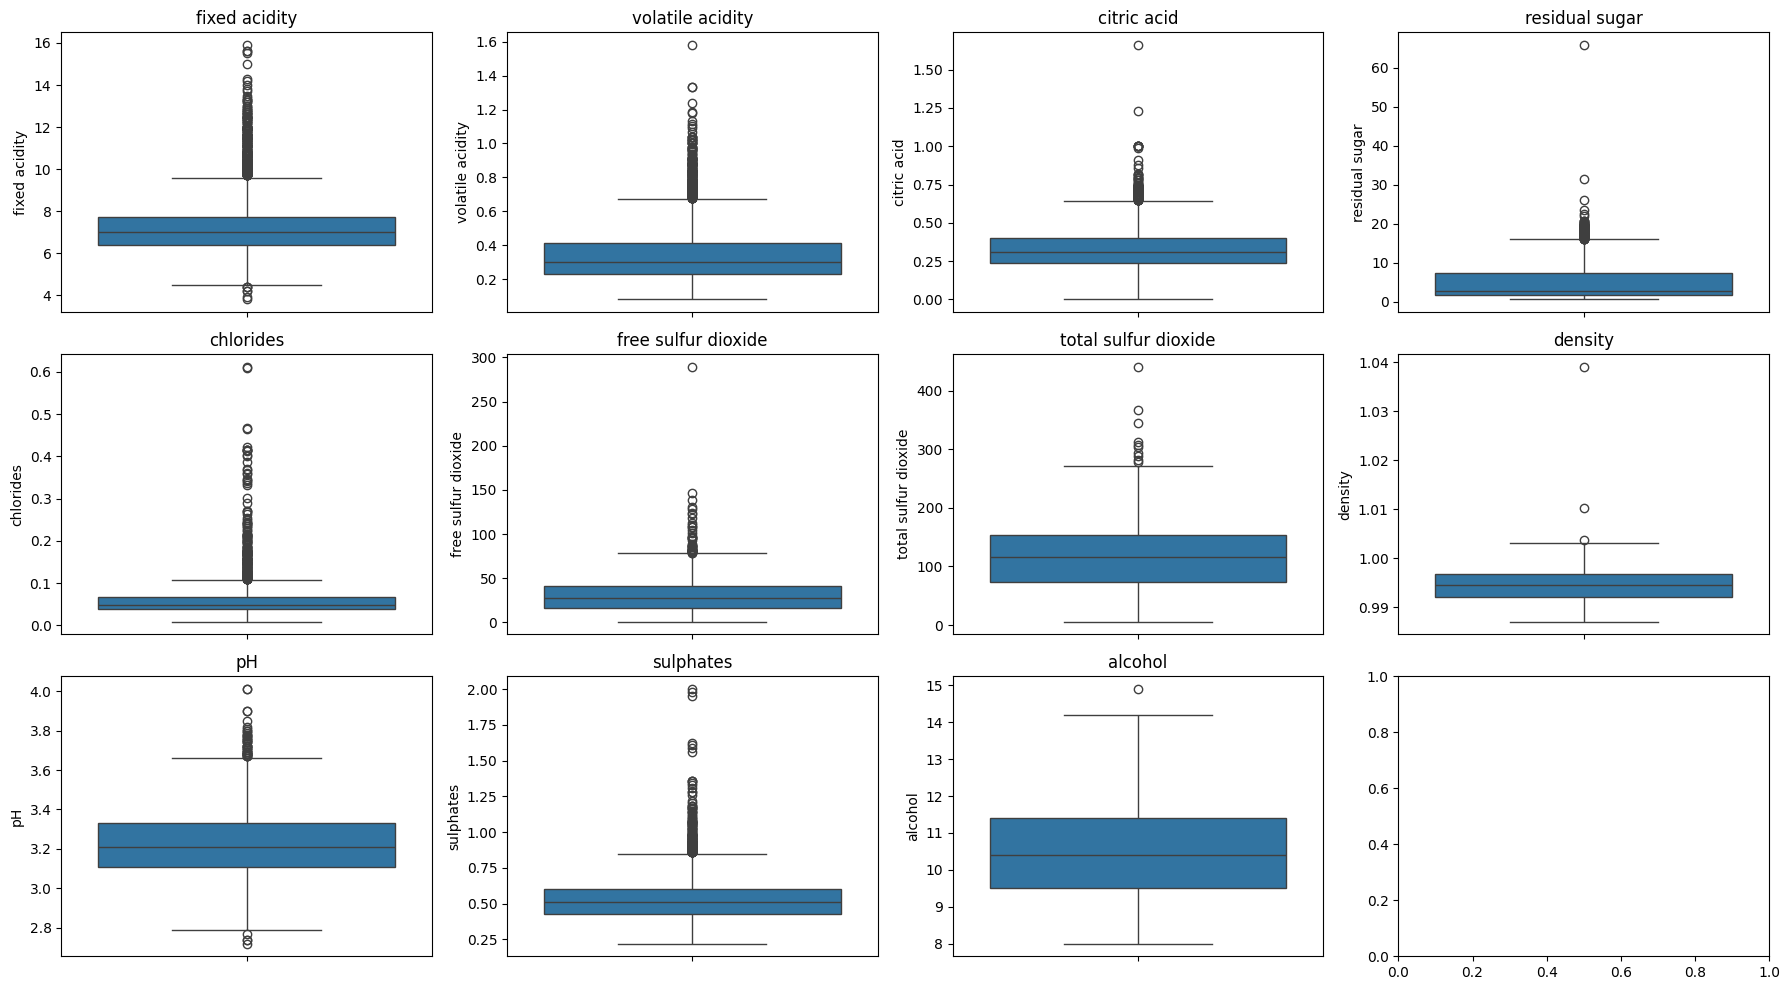

In [7]:
features = df.drop(columns=["quality", "type"]).columns

fig, axes = plt.subplots(3, 4, figsize=(18, 10))
for ax, col in zip(axes.ravel(), features):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [8]:
outliers = {}
for col in features:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    mask = (df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)
    outliers[col] = mask.sum()

pd.Series(outliers).sort_values(ascending=False).to_frame("nb_outliers")


,nb_outliers
fixed acidity,304
volatile acidity,279
chlorides,237
sulphates,163
citric acid,143
residual sugar,141
pH,49
free sulfur dioxide,44
total sulfur dioxide,10
density,3


### 5. Encodage et définition de la cible
**Encodage.** La variable binaire `type` est codée par un indicateur $\text{type\_white}\in\{0,1\}$ ; un seul indicateur suffit pour deux modalités.
**Cible.** Conformément à l'énoncé : $y=\mathbb{1}[\text{quality}\ge 7]$.
**Déséquilibre.** La classe positive représente 19 % des observations (1009 contre 4311). Un classifieur constant (toujours « non bon ») atteindrait une accuracy de 81 % sans aucun pouvoir discriminant : l'accuracy n'est donc pas un critère pertinent.
**Décisions.** (i) découpage et validation croisée **stratifiés** pour conserver la proportion de classes ; (ii) pondération des erreurs par $w_c=\dfrac{n}{K\,n_c}$ (`class_weight="balanced"`) ; (iii) évaluation par précision, rappel, F1 et AUC.

good
0    4311
1    1009
Name: count, dtype: int64
good
0    0.81
1    0.19
Name: proportion, dtype: float64


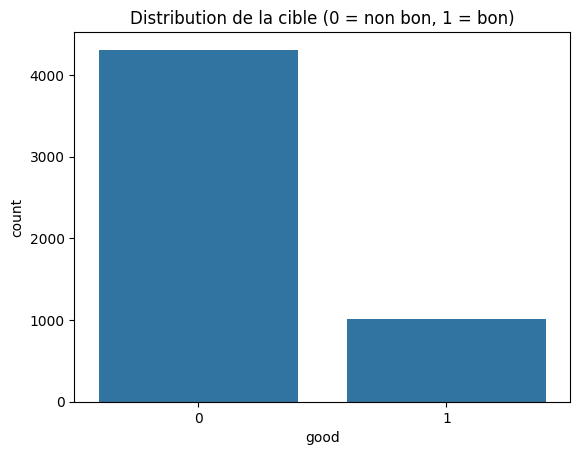

In [10]:
df["type_white"] = (df["type"] == "white").astype(int)
df["good"] = (df["quality"] >= 7).astype(int)

print(df["good"].value_counts())
print(df["good"].value_counts(normalize=True).round(3))

sns.countplot(x="good", data=df)
plt.title("Distribution de la cible (0 = non bon, 1 = bon)")
plt.show()

### 6. Analyse exploratoire
**Distributions.** Les histogrammes permettent d'évaluer l'asymétrie ($\gamma_1$) et la multimodalité des variables, ce qui conditionne la pertinence des hypothèses paramétriques (loi normale conditionnelle de Naive Bayes).
**Corrélations.** Le coefficient de Pearson mesure la dépendance linéaire entre deux variables ; avec la cible binaire, il correspond au coefficient point-bisérial. Il permet de (i) identifier les variables informatives et (ii) détecter la **multicolinéarité** (ex. `free`/`total sulfur dioxide` : 0,72 ; `alcohol`/`density` : −0,67), qui déstabilise l'estimation des coefficients des modèles linéaires.
**Limite.** Le coefficient de Pearson ne capte pas les relations non linéaires ; une variable faiblement corrélée peut rester utile à un modèle non linéaire.

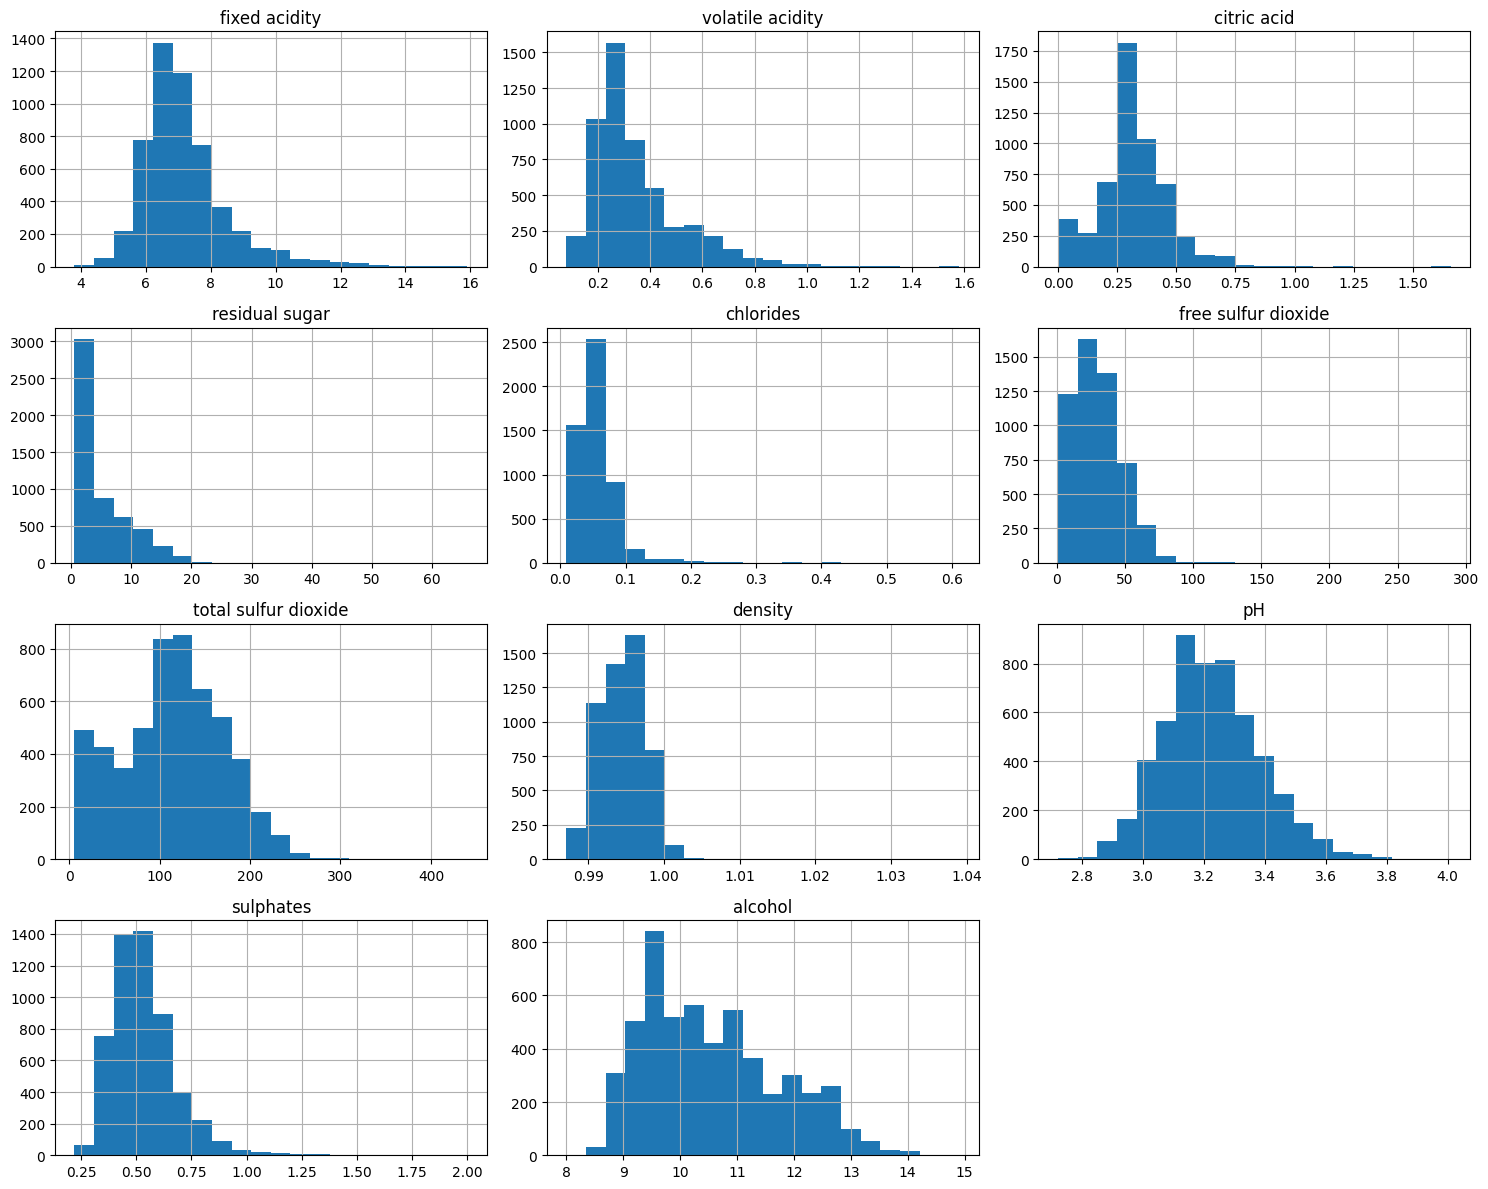

In [11]:
# Histogrammes des variables numériques

features = df.drop(columns=["quality", "type", "good", "type_white"]).columns

df[features].hist(figsize=(15, 12), bins=20)

plt.tight_layout()
plt.show()

### 6.2 Matrice de corrélation


**Comment lire la matrice.** Rouge : les deux variables varient dans le même sens (r > 0). Bleu : elles varient en sens inverse (r < 0). Plus la couleur est foncée, plus le lien est fort ; proche de 0 (blanc), il n'y a pas de lien linéaire.

#### Ce que l'on observe

**1. Liens avec la cible (« bon vin »).**

| Variable | r avec `good` | Lecture |
|---|---|---|
| `alcohol` | **+0,42** | Plus un vin est alcoolisé, plus il est souvent jugé bon |
| `density` | **−0,29** | Les vins moins denses sont plus souvent bons |
| `chlorides` | −0,16 | Effet négatif modeste |
| `volatile acidity` | −0,14 | Effet négatif modeste (acidité volatile élevée = défaut de goût) |
| `residual sugar`, `total sulfur dioxide`, `fixed acidity` | −0,09 à −0,05 | Quasi nul |
| `type_white`, `citric acid`, `pH`, `sulphates`, `free sulfur dioxide` | +0,08 à +0,01 | Quasi nul |

Une seule variable ressort nettement (`alcohol`). Même elle n'explique qu'environ 17 % de la variance de la cible de façon linéaire (0,42² ≈ 0,17). Aucune variable ne suffit à prédire la qualité : cela **annonce un problème difficile**, ce que confirment les F1 d'environ 0,55 obtenus plus loin.

**2. Redondances entre variables explicatives.**

| Paire | r | Explication probable |
|---|---|---|
| `free` / `total sulfur dioxide` | +0,72 | Le SO₂ libre est une partie du SO₂ total |
| `alcohol` / `density` | −0,67 | L'alcool est moins dense que l'eau : plus d'alcool, densité plus faible |
| `total sulfur dioxide` / `type_white` | +0,69 | Les blancs contiennent nettement plus de SO₂ que les rouges |
| `volatile acidity` / `type_white` | −0,65 | Les rouges ont une acidité volatile plus élevée |

Les deux dernières paires viennent du **mélange des vins rouges et blancs** : `type_white` résume à lui seul une partie des différences chimiques entre les deux populations.

#### Ce que cela signifie pour la suite

- **Multicolinéarité.** Quand deux variables sont très liées, la régression logistique ne sait plus à laquelle attribuer l'effet : ses coefficients deviennent instables et leur lecture doit rester prudente. Les arbres, le SVM et le k-NN en souffrent moins pour prédire, mais pas pour l'interprétation.
- **Choix de la sélection de variables.** Le filtre de Pearson classe chaque variable **séparément** : il garde `alcohol` et `density` sans voir qu'elles sont redondantes. C'est une limite des filtres univariés.
- **Variables faiblement corrélées ≠ inutiles.** Pearson ne capte que les liens linéaires. Une variable avec r ≈ 0 peut servir à un modèle non linéaire (arbre, SVM à noyau, k-NN) par ses interactions avec d'autres variables. Les modèles optimisés gardent d'ailleurs 11 à 12 variables sur 12.
- **Corrélation n'est pas causalité.** Un lien entre alcool et qualité décrit une association dans ces données, pas un effet démontré. Les dégustateurs peuvent aussi noter mieux les vins plus puissants, ou le type de vin peut jouer un rôle de variable cachée.
- **Calcul sur l'ensemble des données.** Cette analyse exploratoire utilise tout le jeu (après suppression des doublons) pour comprendre les données. Le filtre de sélection, lui, recalcule les corrélations **sur l'entraînement uniquement**, pour éviter toute fuite vers le test.

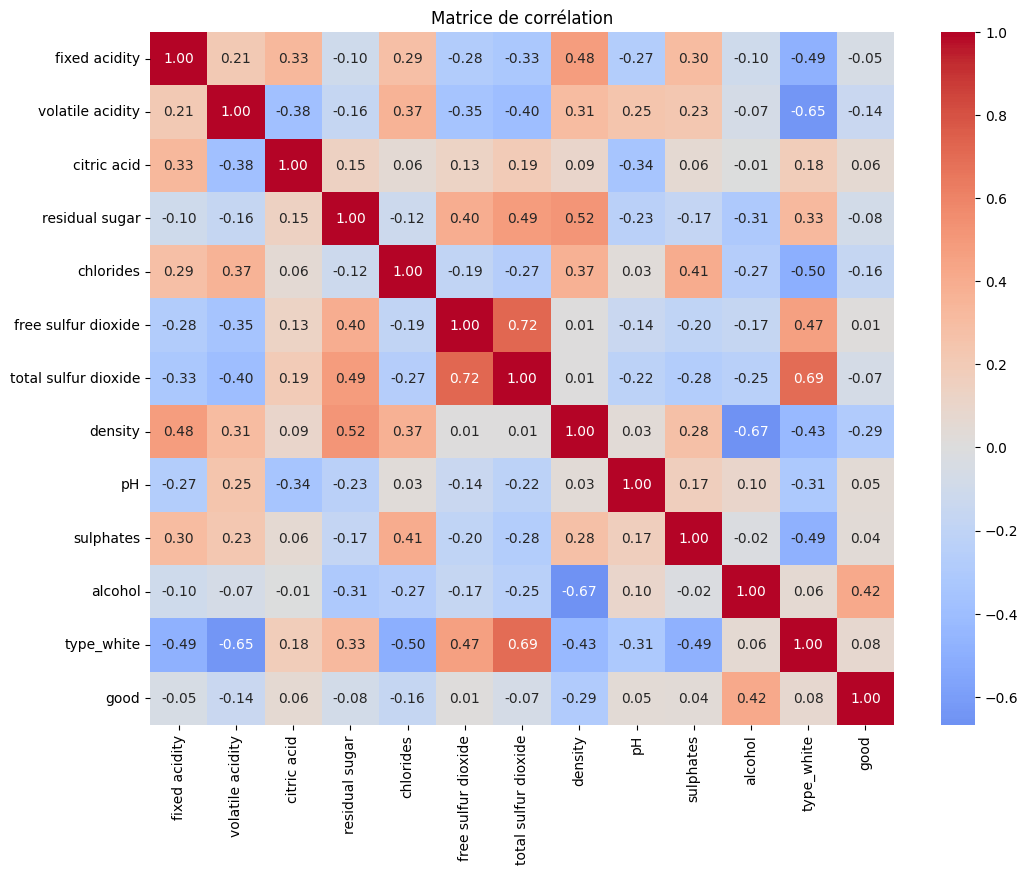

alcohol                 0.417743
type_white              0.081083
citric acid             0.060672
pH                      0.048330
sulphates               0.036771
free sulfur dioxide     0.011325
fixed acidity          -0.049841
total sulfur dioxide   -0.067307
residual sugar         -0.084868
volatile acidity       -0.144361
chlorides              -0.161027
density                -0.294971
Name: good, dtype: float64

In [13]:
cols = list(features) + ["type_white", "good"]
corr = df[cols].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matrice de corrélation")
plt.show()

corr["good"].drop("good").sort_values(ascending=False)

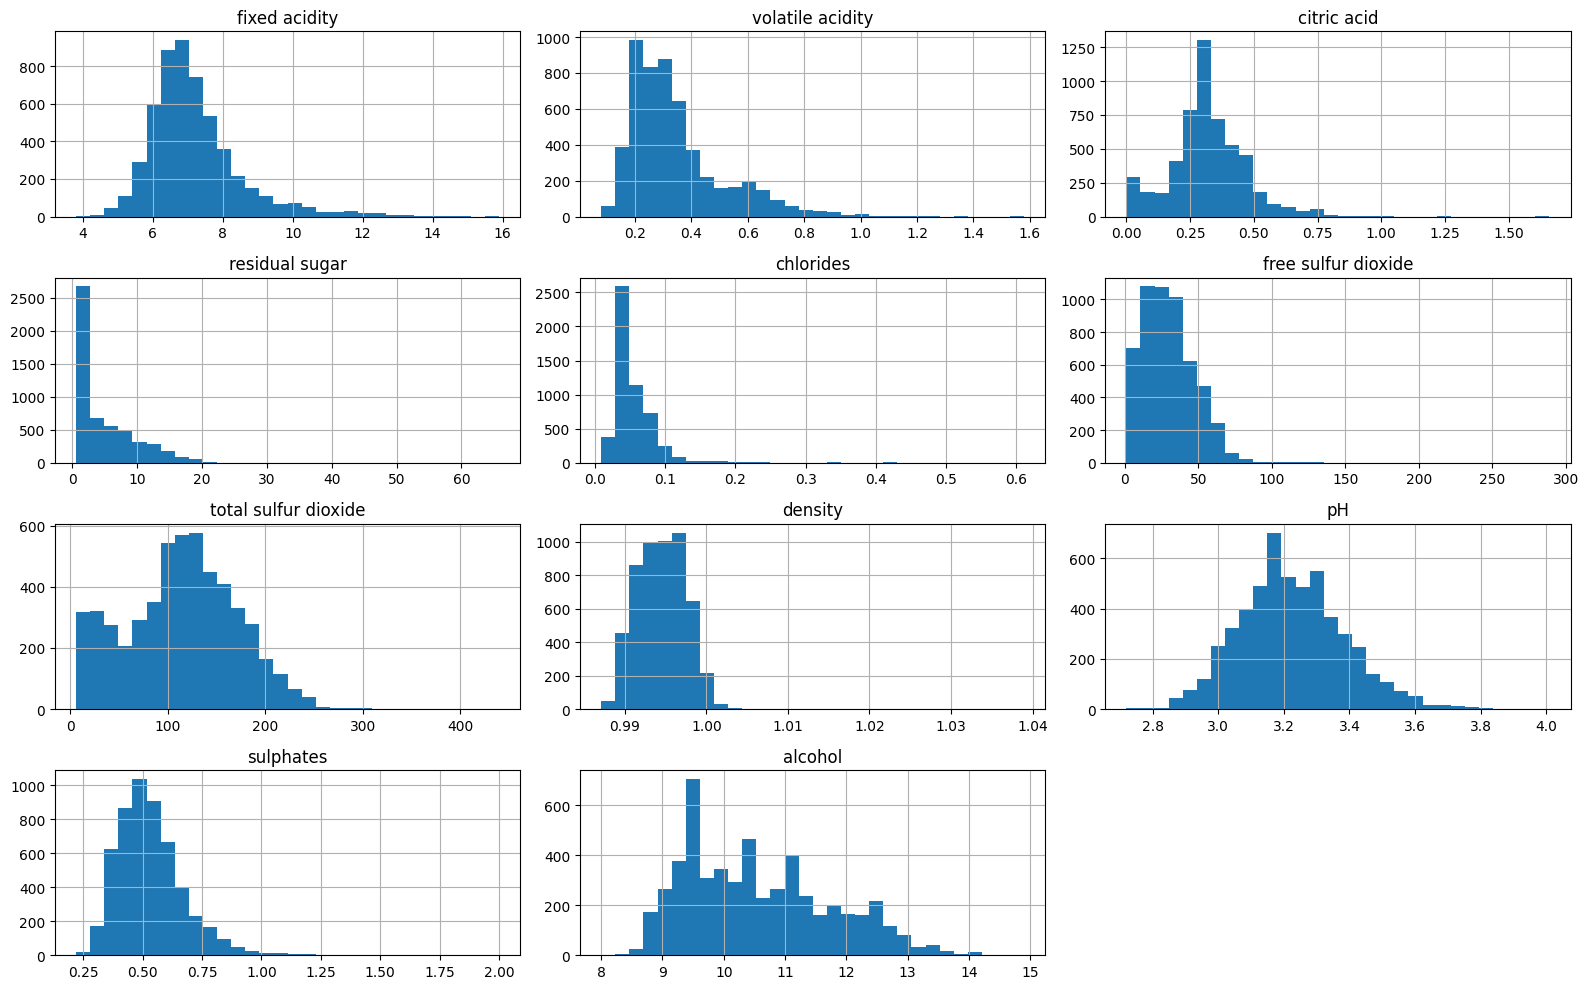

In [16]:
df[features].hist(bins=30, figsize=(16, 10))
plt.tight_layout()
plt.show()

### 7. Découpage entraînement / test
**Méthode.** Découpage 80/20 stratifié (`random_state=42` pour la reproductibilité) : 4256 observations d'entraînement, 1064 de test.
**Justification.** Le jeu de test sert à estimer l'erreur de généralisation $\mathbb{E}[\ell(y,\hat f(x))]$ sur des données non utilisées pour l'apprentissage. Pour que cette estimation soit sans biais, **aucune** étape ajustée sur les données (corrélations, standardisation, sélection de variables, choix des hyperparamètres) ne doit utiliser le jeu de test.

In [18]:
from wine import prepare, split, make_pipe

X, y = prepare(df)
X_train, X_test, y_train, y_test = split(X, y)

print(X_train.shape, X_test.shape)

(4256, 12) (1064, 12)


In [19]:
# Feature Selection - Méthode Filter avec corrélation de Pearson

train_data = X_train.copy()
train_data["good"] = y_train

corr_train = train_data.corr()

correlations = (
    corr_train["good"]
    .drop("good")
    .abs()
    .sort_values(ascending=False)
)

display(correlations.to_frame("abs_correlation"))

,abs_correlation
alcohol,0.422594
density,0.297680
chlorides,0.158681
volatile acidity,0.142750
residual sugar,0.085749
type_white,0.080539
total sulfur dioxide,0.074100
citric acid,0.058113
fixed acidity,0.042601
pH,0.041527


### 8. Sélection de variables
**Objectif.** Réduire la dimension afin de limiter le bruit, la redondance et la variance, et de faciliter l'interprétation.
**Méthode 1 : filtre de Pearson.** On retient les variables telles que $|r(x_j,y)|\ge\tau$, avec $r$ calculé **sur le jeu d'entraînement uniquement**. Plusieurs seuils sont comparés par validation croisée (tableau ci-après), ce qui justifie le choix de $\tau=0{,}05$ (8 variables).
**Méthode 2 : `SelectKBest` (test $F$ de l'ANOVA)**, placée dans le Pipeline : $k$ est un hyperparamètre optimisé, et la sélection est réajustée à chaque pli de la validation croisée.
**Limites.** Ce sont des filtres univariés : ils ignorent les interactions entre variables et la redondance. De plus, dans la comparaison des seuils, les corrélations sont calculées sur l'ensemble du jeu d'entraînement avant la validation croisée : l'estimation des scores est légèrement optimiste. La méthode 2 n'a pas ce défaut.

In [20]:
threshold = 0.03

selected_features = correlations[
    correlations >= threshold
].index.tolist()

print("Variables sélectionnées :", selected_features)
print("Nombre de variables :", len(selected_features))

Variables sélectionnées : ['alcohol', 'density', 'chlorides', 'volatile acidity', 'residual sugar', 'type_white', 'total sulfur dioxide', 'citric acid', 'fixed acidity', 'pH', 'sulphates']
Nombre de variables : 11


In [21]:
X_train_selected = X_train[selected_features]
X_test_selected = X_test[selected_features]

print("X_train :", X_train_selected.shape)
print("X_test :", X_test_selected.shape)

X_train : (4256, 11)
X_test : (1064, 11)


In [22]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

In [23]:
X_train_scaled = scaler.fit_transform(X_train_selected)
X_test_scaled = scaler.transform(X_test_selected)

In [24]:
print(X_train_scaled.mean(axis=0).round(3))
print(X_train_scaled.std(axis=0).round(3))

[ 0.  0.  0.  0.  0. -0.  0.  0.  0.  0. -0.]
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


### 9. Choix et justification des modèles

#### Ce que l'on sait de nos données

| Caractéristique | Observation | Conséquence pour le choix |
|---|---|---|
| Variables continues, échelles très différentes | `total sulfur dioxide` jusqu'à 440, `density` entre 0,987 et 1,039 | Les modèles à distances ou à régularisation exigent une standardisation |
| Distributions asymétriques à droite, valeurs extrêmes conservées | `residual sugar`, `chlorides`, `sulphates`… | Hypothèse gaussienne douteuse ; les modèles à base d'arbres sont plus robustes |
| Variables corrélées entre elles | `free`/`total sulfur dioxide` (0,72), `alcohol`/`density` (−0,67) | Hypothèse d'indépendance fragile ; coefficients linéaires instables |
| Signal faible | meilleure corrélation avec la cible : `alcohol` (0,42) | Un modèle simple risque le biais ; un modèle trop souple, la variance |
| Classes déséquilibrées | 19 % de bons vins | Pondération des classes et critère F1 |
| Taille modérée | 4256 observations d'entraînement, 12 variables | Les modèles à noyau et le k-NN restent calculables |

#### Les cinq modèles de base 

**Régression logistique (linéaire, paramétrique).** Elle modélise le log-odds de « bon vin » comme une combinaison linéaire des variables, donc une frontière de décision **linéaire**. Points forts : peu de variance, coefficients interprétables, sortie probabiliste. Limites : elle ne capte ni les non-linéarités ni les interactions, et la colinéarité rend les coefficients instables. Elle sert de **référence** : si un modèle plus complexe ne la dépasse pas nettement, la complexité n'est pas justifiée. Hyperparamètre : `C` (inverse de la régularisation L2). On attend un biais élevé et une variance faible.

**k plus proches voisins (non paramétrique, non linéaire).** Il classe un vin selon la majorité de ses *k* voisins : la frontière est **locale et très flexible**, sans hypothèse sur la forme des données. Il repose sur des distances, donc exige la standardisation, et il est sensible aux variables peu informatives et au bruit (un *k* petit mène à une variance élevée). Il n'a pas de pondération des classes : avec 19 % de positifs, les voisins sont majoritairement « non bon », ce qui pénalise le rappel. Hyperparamètres : `n_neighbors`, `weights`. On attend une variance élevée.

**Arbre de décision (non linéaire, non paramétrique).** Il découpe l'espace par des seuils successifs : frontière **constante par morceaux**, capable de capter interactions et non-linéarités, **invariante aux transformations monotones** des variables (pas de standardisation nécessaire) et peu sensible aux valeurs extrêmes. Il est facile à interpréter, mais **instable** : un petit changement des données peut changer l'arbre (variance élevée si la profondeur n'est pas limitée). Hyperparamètres : `max_depth`, `min_samples_leaf`. On attend un modèle interprétable mais limité en performance.

**Naive Bayes gaussien (probabiliste, génératif).** Il applique le théorème de Bayes en supposant que, **dans chaque classe, les variables sont indépendantes et gaussiennes**. La frontière est quadratique. Il est très rapide et très stable, mais **nos données violent ses deux hypothèses** : distributions asymétriques et variables corrélées. On attend un biais élevé : il sert surtout de point de comparaison probabiliste. Hyperparamètre : `var_smoothing`.

**SVM à noyau RBF (non linéaire, à marge maximale).** Il cherche l'hyperplan de marge maximale dans un espace de grande dimension défini par le noyau gaussien : frontière **non linéaire lisse**. La marge souple (`C`) le rend tolérant au bruit, et `gamma` règle la localité de la frontière. Il exige la standardisation, accepte la pondération des classes (`class_weight="balanced"`) et reste calculable à notre taille. On attend un bon compromis biais/variance. Hyperparamètres : `C`, `gamma`.

#### Deux modèles complémentaires

Ils servent à vérifier si les cinq modèles imposés atteignent un **plafond** lié aux données ou à leur nature.

**Random Forest.** Moyenne de nombreux arbres profonds entraînés sur des échantillons *bootstrap* : la moyenne **réduit la variance** des arbres, tout en captant interactions et non-linéarités. Robuste aux valeurs extrêmes et aux échelles, mais moins interprétable. Hyperparamètres : `max_depth`, `min_samples_leaf`, `max_features`.

**Gradient Boosting.** Arbres peu profonds construits **séquentiellement**, chacun corrigeant les erreurs du précédent : il **réduit le biais** et atteint souvent les meilleures performances sur données tabulaires, au prix d'un risque de surapprentissage et d'un réglage plus délicat. Hyperparamètres : `learning_rate`, `max_depth`, `min_samples_leaf`.

#### Synthèse

| Modèle | Frontière | Standardisation nécessaire | Robuste aux valeurs extrêmes | Hypothèse forte | Risque principal |
|---|---|---|---|---|---|
| Régression logistique | Linéaire | Oui | Moyen | Log-odds linéaire | Biais |
| k-NN | Locale, flexible | **Oui** | Non | Voisins proches = même classe | Variance, déséquilibre |
| Arbre de décision | Constante par morceaux | Non | **Oui** | Aucune | Variance |
| Naive Bayes | Quadratique | Non | Non | **Indépendance + gaussienne** | Biais (hypothèses violées) |
| SVM RBF | Non linéaire lisse | **Oui** | Moyen | Régularité du noyau | Réglage de `C` et `gamma` |
| Random Forest | Non linéaire | Non | **Oui** | Aucune | Variance résiduelle, interprétabilité |
| Gradient Boosting | Non linéaire | Non | Oui | Aucune | Surapprentissage |


In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

models = {
    "Régression logistique": LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ),

    "k-NN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Arbre de décision": DecisionTreeClassifier(
        criterion="entropy",
        max_depth=5,
        class_weight="balanced",
        random_state=42
    ),

    "Naive Bayes": GaussianNB(),

    "SVM (RBF)": SVC(
        class_weight="balanced"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced_subsample",
        random_state=42
    ),

    "Gradient Boosting": HistGradientBoostingClassifier(
        class_weight="balanced",
        random_state=42
    )
}

In [26]:
predictions = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    predictions[name] = model.predict(X_test_scaled)

print("Entraînement terminé.")

Entraînement terminé.


### 11. Métriques d'évaluation
Avec 19 % de positifs, l'accuracy est trompeuse. Nous retenons : la **précision** $\frac{TP}{TP+FP}$, le **rappel** $\frac{TP}{TP+FN}$, leur moyenne harmonique le **F1**, et l'**AUC** $=P(s^+>s^-)$, indépendante du seuil de décision. La matrice de confusion détaille la nature des erreurs, la courbe ROC le compromis $TPR$/$FPR$.
**Critère principal.** Le F1 de la classe « bon » : il pénalise un modèle dont la précision ou le rappel est faible.

In [27]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

rows = []

for name, model in models.items():
    y_pred = predictions[name]

    if hasattr(model, "decision_function"):
        y_score = model.decision_function(X_test_scaled)
    else:
        y_score = model.predict_proba(X_test_scaled)[:, 1]

    rows.append({
        "Modèle": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Précision": precision_score(y_test, y_pred),
        "Rappel": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "AUC": roc_auc_score(y_test, y_score)
    })

results = pd.DataFrame(rows).set_index("Modèle").round(3)

display(results)

,Accuracy,Précision,Rappel,F1,AUC
Modèle,,,,,
Régression logistique,0.723,0.385,0.772,0.514,0.815
k-NN,0.830,0.571,0.416,0.481,0.820
Arbre de décision,0.673,0.349,0.832,0.491,0.788
Naive Bayes,0.730,0.376,0.639,0.473,0.759
SVM (RBF),0.718,0.386,0.822,0.525,0.847
Random Forest,0.841,0.677,0.312,0.427,0.869
Gradient Boosting,0.810,0.500,0.668,0.572,0.844


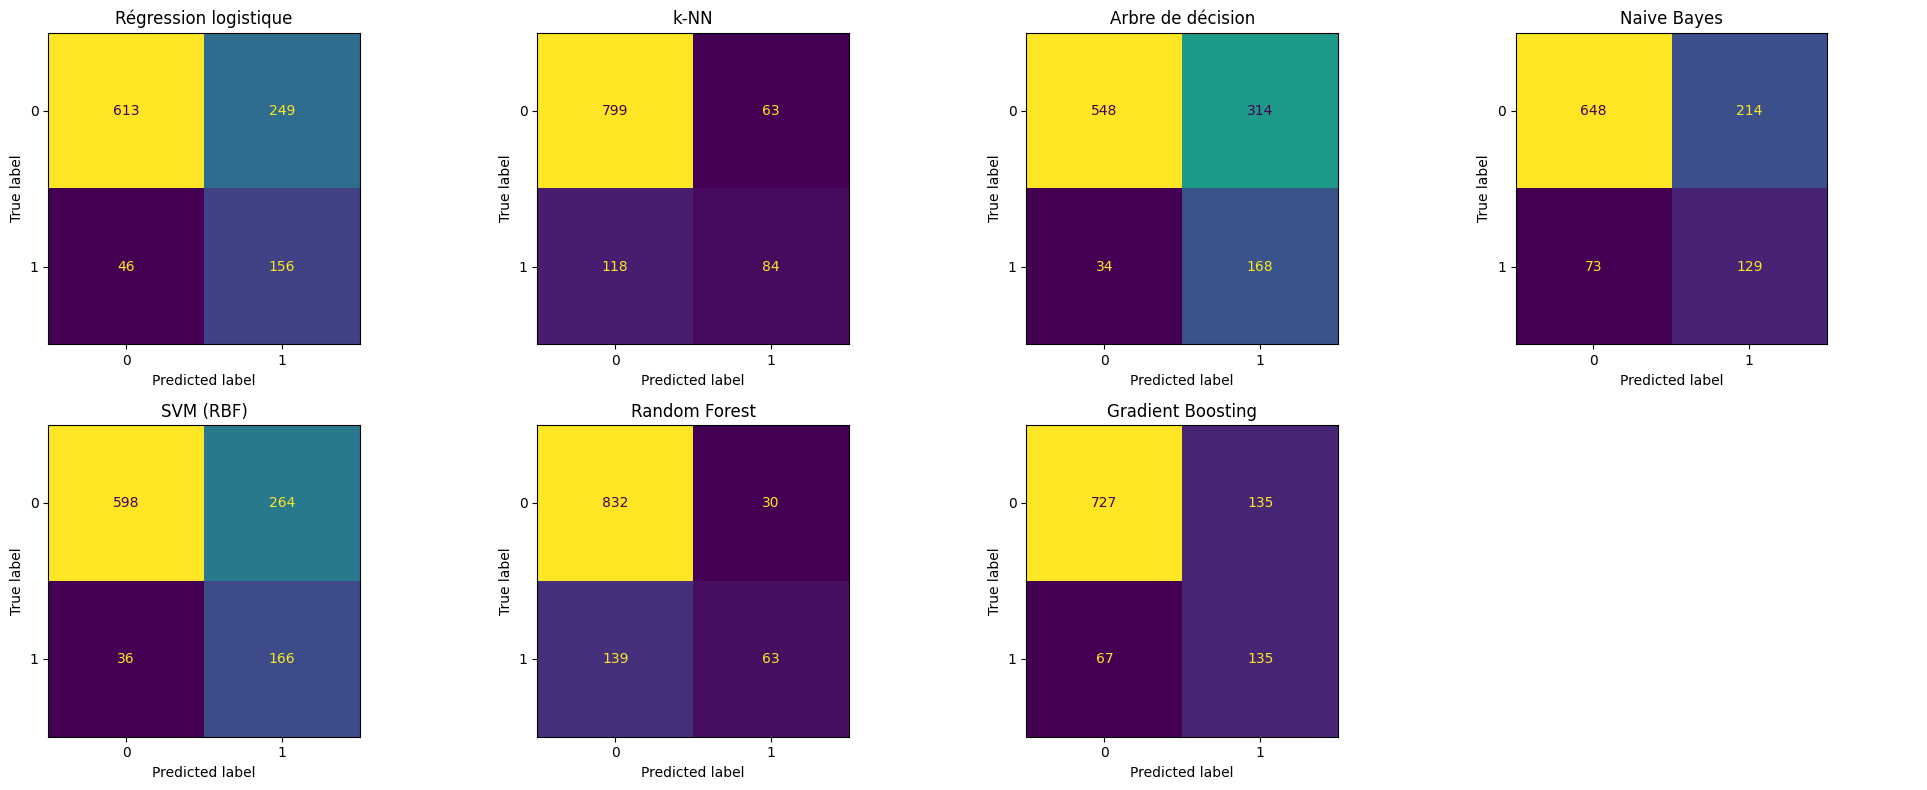

In [28]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

n = len(models)
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
axes = axes.ravel()

for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions[name],
        ax=ax,
        colorbar=False
    )
    ax.set_title(name)

# cache la case vide (7 modèles pour 8 cases)
for ax in axes[n:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

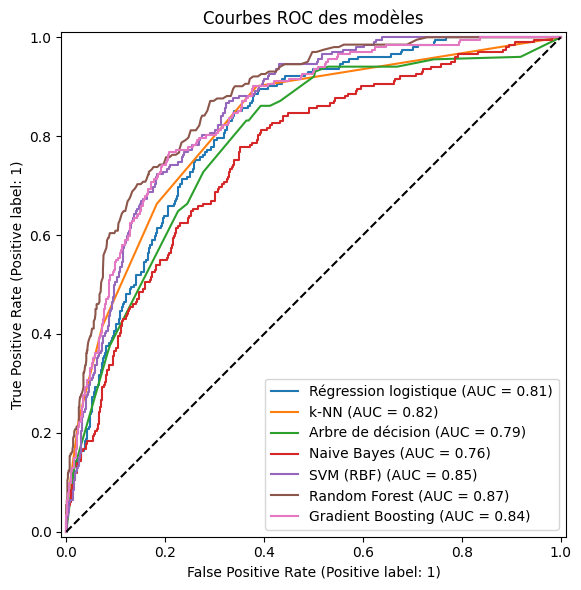

In [29]:
from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 6))

for name, model in models.items():
    RocCurveDisplay.from_estimator(
        model,
        X_test_scaled,
        y_test,
        name=name,
        ax=ax
    )

ax.plot([0, 1], [0, 1], "k--")
ax.set_title("Courbes ROC des modèles")
plt.tight_layout()
plt.show()

### 12. Optimisation des hyperparamètres
**Validation croisée stratifiée (5 plis).** Elle estime l'erreur de généralisation sans toucher au jeu de test, et fournit un écart-type qui quantifie la stabilité.
**Grid Search** (exhaustif) et **Random Search** (20 tirages ; `loguniform` pour $C$ et $\gamma$, qui varient sur plusieurs ordres de grandeur) sont comparés. Le Random Search est plus économique lorsque peu d'hyperparamètres influencent réellement la performance (Bergstra et Bengio, 2012).
**Pipeline.** Standardisation, `SelectKBest` et modèle sont chaînés : chaque étape est réajustée sur les seuls plis d'entraînement, ce qui supprime la fuite d'information vers les plis de validation.
**Critère.** Le F1, adapté au déséquilibre. Le modèle retenu pour chaque famille est celui du **meilleur F1 en validation croisée**, jamais celui du test.
**Limite.** Les mêmes plis servent au réglage et au rapport du score : celui-ci est légèrement optimiste (une validation croisée imbriquée l'éviterait).

In [30]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import StratifiedKFold, GridSearchCV, RandomizedSearchCV, cross_val_score
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from scipy.stats import loguniform, randint


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

k_grid = [6, 8, 12]
specs = {
    "Régression logistique": (
        LogisticRegression(max_iter=1000, class_weight="balanced"),
        {"select__k": k_grid, "clf__C": [0.01, 0.1, 1, 10, 100]},
        {"select__k": randint(4, 13), "clf__C": loguniform(1e-3, 1e2)}),
    "k-NN": (
        KNeighborsClassifier(),
        {"select__k": k_grid, "clf__n_neighbors": [5, 11, 15, 20], "clf__weights": ["uniform", "distance"]},
        {"select__k": randint(4, 13), "clf__n_neighbors": randint(3, 31), "clf__weights": ["uniform", "distance"]}),
    "Arbre de décision": (
        DecisionTreeClassifier(class_weight="balanced", random_state=42),
        {"select__k": k_grid, "clf__max_depth": [3, 5, 7, 10], "clf__min_samples_leaf": [1, 5, 10]},
        {"select__k": randint(4, 13), "clf__max_depth": randint(3, 15), "clf__min_samples_leaf": randint(1, 20)}),
    "Naive Bayes": (
        GaussianNB(),
        {"select__k": k_grid, "clf__var_smoothing": [1e-9, 1e-7, 1e-5]},
        {"select__k": randint(4, 13), "clf__var_smoothing": loguniform(1e-12, 1e-4)}),
    "SVM": (
        SVC(class_weight="balanced"),
        {"select__k": k_grid, "clf__C": [0.1, 1, 10], "clf__gamma": ["scale", 0.01, 0.1]},
        {"select__k": randint(4, 13), "clf__C": loguniform(1e-2, 1e2), "clf__gamma": loguniform(1e-3, 1)}),
    "Random Forest": (
        RandomForestClassifier(class_weight="balanced_subsample", random_state=42),
        {"select__k": [8, 12], "clf__n_estimators": [300],
         "clf__max_depth": [6, 10, None], "clf__min_samples_leaf": [1, 5]},
        {"select__k": randint(4, 13), "clf__n_estimators": randint(200, 600),
         "clf__max_depth": [None, 6, 10, 14], "clf__min_samples_leaf": randint(1, 10),
         "clf__max_features": ["sqrt", 0.5]}),
    "Gradient Boosting": (
        HistGradientBoostingClassifier(class_weight="balanced", random_state=42),
        {"select__k": [8, 12], "clf__learning_rate": [0.05, 0.1],
         "clf__max_depth": [3, None], "clf__min_samples_leaf": [20, 50]},
        {"select__k": randint(4, 13), "clf__learning_rate": loguniform(0.02, 0.3),
         "clf__max_iter": randint(100, 500), "clf__max_depth": [3, 4, 6, None],
         "clf__min_samples_leaf": randint(10, 60), "clf__l2_regularization": loguniform(1e-3, 10)}),
}
print("Pipelines et grilles définis :", list(specs))

Pipelines et grilles définis : ['Régression logistique', 'k-NN', 'Arbre de décision', 'Naive Bayes', 'SVM', 'Random Forest', 'Gradient Boosting']


In [31]:
rows = []
for t in [0.03, 0.05, 0.08, 0.1, 0.15]:
    feats = correlations[correlations >= t].index.tolist()
    for name, clf in [
        ("Régression logistique", LogisticRegression(max_iter=1000, class_weight="balanced")),
        ("k-NN", KNeighborsClassifier(n_neighbors=5)),
        ("Arbre de décision", DecisionTreeClassifier(criterion="entropy", max_depth=5, class_weight="balanced", random_state=42)),
        ("Naive Bayes", GaussianNB()),
        ("SVM", SVC(class_weight="balanced")),
        ("Random Forest", RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample", random_state=42, n_jobs=-1)),
        ("Gradient Boosting", HistGradientBoostingClassifier(class_weight="balanced", random_state=42)),
    ]:
        pipe = Pipeline([("scaler", StandardScaler()), ("clf", clf)])
        s = cross_val_score(pipe, X_train[feats], y_train, cv=cv, scoring="f1")
        rows.append({"Seuil": t, "Nb variables": len(feats), "Modèle": name,
                     "F1 CV": round(s.mean(), 3), "Écart-type": round(s.std(), 3)})

res = pd.DataFrame(rows)
display(res.pivot(index="Modèle", columns="Nb variables", values="F1 CV"))

Nb variables,3,4,6,8,11
Modèle,,,,,
Arbre de décision,0.495,0.512,0.507,0.487,0.489
Gradient Boosting,0.502,0.519,0.527,0.539,0.542
Naive Bayes,0.493,0.499,0.489,0.494,0.499
Random Forest,0.364,0.393,0.386,0.427,0.421
Régression logistique,0.512,0.522,0.526,0.527,0.531
SVM,0.511,0.515,0.519,0.521,0.539
k-NN,0.359,0.396,0.429,0.454,0.470


In [33]:
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score

for name, clf in [("SVM", SVC(class_weight="balanced")), ("k-NN", KNeighborsClassifier(n_neighbors=5))]:
    brut = cross_val_score(clf, X_train, y_train, cv=cv, scoring="f1").mean()
    std = cross_val_score(make_pipeline(StandardScaler(), clf), X_train, y_train, cv=cv, scoring="f1").mean()
    print(f"{name}: sans standardisation {brut:.3f} | avec {std:.3f}")

SVM: sans standardisation 0.416 | avec 0.545
k-NN: sans standardisation 0.281 | avec 0.477


### 13. Évaluation finale sur le jeu de test
Les modèles retenus sont évalués **une seule fois** sur le jeu de test. Avec environ 200 observations positives, les écarts de quelques millièmes de F1 ne sont pas significatifs : la comparaison s'appuie donc aussi sur l'écart-type de la validation croisée et sur l'AUC. L'écart entre F1 d'entraînement et F1 de test sert d'indicateur de surapprentissage.

In [35]:
searches = {}
for name, (clf, grid, dist) in specs.items():
    for method in ["Grid Search", "Random Search"]:
        pipe = make_pipe(clf)
        if method == "Grid Search":
            s = GridSearchCV(pipe, grid, cv=cv, scoring="f1", n_jobs=-1)
        else:
            s = RandomizedSearchCV(pipe, dist, n_iter=20, cv=cv, scoring="f1",
                                   random_state=42, n_jobs=-1)
        s.fit(X_train, y_train)
        searches[(name, method)] = s
        print(f"{name:22s} {method:14s} F1 CV = {s.best_score_:.3f}")

/Users/amine/projet_vin/venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/amine/projet_vin/venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/amine/projet_vin/venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/amine/projet_vin/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/amine/projet_vin/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/amine/projet_vin/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value enc

Régression logistique  Grid Search    F1 CV = 0.539
Régression logistique  Random Search  F1 CV = 0.538


/Users/amine/projet_vin/venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/amine/projet_vin/venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/amine/projet_vin/venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/amine/projet_vin/venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: overflow encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/amine/projet_vin/venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: invalid value encountered in matmul
  grad[:n_features] = X.T 

k-NN                   Grid Search    F1 CV = 0.492
k-NN                   Random Search  F1 CV = 0.476
Arbre de décision      Grid Search    F1 CV = 0.513
Arbre de décision      Random Search  F1 CV = 0.515
Naive Bayes            Grid Search    F1 CV = 0.496
Naive Bayes            Random Search  F1 CV = 0.500
SVM                    Grid Search    F1 CV = 0.546
SVM                    Random Search  F1 CV = 0.533
Random Forest          Grid Search    F1 CV = 0.562
Random Forest          Random Search  F1 CV = 0.561
Gradient Boosting      Grid Search    F1 CV = 0.551
Gradient Boosting      Random Search  F1 CV = 0.537


### Sélection du meilleur réglage de chaque modèle
Pour chaque couple (modèle, méthode de recherche), le tableau reporte le F1 moyen en validation croisée stratifiée à 5 plis, son écart-type sur les plis et les hyperparamètres optimaux (y compris le nombre de variables `select__k` retenu par `SelectKBest`).

Pour chaque famille de modèles, on conserve l'estimateur de la recherche (Grid ou Random) qui maximise le **F1 de validation croisée**. Ce choix est fait **sans utiliser le jeu de test**, qui reste réservé à l'évaluation finale. L'estimateur retenu est déjà réentraîné sur l'ensemble du jeu d'entraînement avec les hyperparamètres optimaux (`best_estimator_`).

In [36]:
rows = []
for (name, method), s in searches.items():
    rows.append({"Modèle": name, "Méthode": method,
                 "F1 CV (moy)": s.best_score_,
                 "F1 CV (écart-type)": s.cv_results_["std_test_score"][s.best_index_],
                 "Paramètres": s.best_params_})
cv_table = pd.DataFrame(rows).sort_values("F1 CV (moy)", ascending=False)
display(cv_table.round(3))

# un seul modèle final par famille : celui qui a le meilleur F1 en CV
best_models = {}
for name in specs:
    best_s = max((s for (n, m), s in searches.items() if n == name), key=lambda s: s.best_score_)
    best_models[name] = best_s.best_estimator_
print("Modèles retenus :", list(best_models))

,Modèle,Méthode,F1 CV (moy),F1 CV (écart-type),Paramètres
10,Random Forest,Grid Search,0.562,0.025,"{'clf__max_depth': None, 'clf__min_samples_lea..."
11,Random Forest,Random Search,0.561,0.023,"{'clf__max_depth': 14, 'clf__max_features': 0...."
12,Gradient Boosting,Grid Search,0.551,0.014,"{'clf__learning_rate': 0.05, 'clf__max_depth':..."
8,SVM,Grid Search,0.546,0.011,"{'clf__C': 1, 'clf__gamma': 0.1, 'select__k': 12}"
0,Régression logistique,Grid Search,0.539,0.020,"{'clf__C': 0.01, 'select__k': 12}"
1,Régression logistique,Random Search,0.538,0.019,"{'clf__C': 0.0745934328572655, 'select__k': 11}"
13,Gradient Boosting,Random Search,0.537,0.018,{'clf__l2_regularization': 0.03480695326785271...
9,SVM,Random Search,0.533,0.010,"{'clf__C': 1.9132683954526488, 'clf__gamma': 0..."
5,Arbre de décision,Random Search,0.515,0.018,"{'clf__max_depth': 3, 'clf__min_samples_leaf':..."
4,Arbre de décision,Grid Search,0.513,0.020,"{'clf__max_depth': 5, 'clf__min_samples_leaf':..."


Modèles retenus : ['Régression logistique', 'k-NN', 'Arbre de décision', 'Naive Bayes', 'SVM', 'Random Forest', 'Gradient Boosting']


### 14. Compromis biais / variance
L'erreur de généralisation se décompose en $\text{Biais}^2+\text{Variance}+\sigma^2$. Un **écart train/test élevé** traduit une variance forte (surapprentissage), alors qu'un **F1 faible à l'entraînement comme au test** traduit un biais fort (sous-apprentissage).

**Lecture des sept modèles (F1 train → test).**
- **k-NN** (1,000 → 0,531, écart 0,469) : variance extrême. Avec `weights="distance"`, chaque point d'entraînement est son propre plus proche voisin.
- **Random Forest** (0,863 → 0,595, écart 0,268) : variance forte, car les arbres profonds mémorisent l'entraînement.
- **Gradient Boosting** (0,711 → 0,590, écart 0,121) : variance intermédiaire.
- **Régression logistique** (0,541 → 0,533, écart 0,007), **arbre de décision** (0,525 → 0,488) et **Naive Bayes** (0,498 → 0,461) : très stables, mais avec un F1 faible dès l'entraînement. C'est un **biais élevé** : leurs hypothèses (frontière linéaire, profondeur limitée, indépendance gaussienne) sont trop rigides pour ce problème.
- **SVM** (0,585 → 0,544, écart 0,041) : variance faible et biais plus modéré que les modèles linéaires, car le noyau RBF capte des non-linéarités.

**Courbes d'apprentissage.** Pour le SVM, les courbes d'entraînement et de validation se rapprochent et la validation est quasi stable vers 0,55. Pour le Random Forest, l'écart reste d'environ 0,30, et pour le Gradient Boosting d'environ 0,19, avec une validation qui progresse encore avec la taille de l'échantillon. Les trois courbes de validation convergent vers un F1 d'environ 0,55 : avec 4256 observations, aucun modèle ne se détache nettement.

**Choix du modèle.** En validation croisée répétée (5×5), les trois meilleurs modèles sont statistiquement indiscernables (SVM 0,546 ± 0,014, Gradient Boosting 0,550 ± 0,018, Random Forest 0,555 ± 0,026 ; aucun n'est meilleur que les autres dans plus de 68 % des plis). Nous les départageons par le compromis biais/variance : le **SVM** est le plus stable (écart-type le plus faible, écart train/test le plus petit) tout en étant moins complexe. L'avantage des modèles d'ensemble sur le jeu de test (F1 de 0,59 contre 0,54) n'est pas confirmé par la validation croisée : avec environ 200 bons vins dans le test, il reflète probablement en partie la composition de cet échantillon.

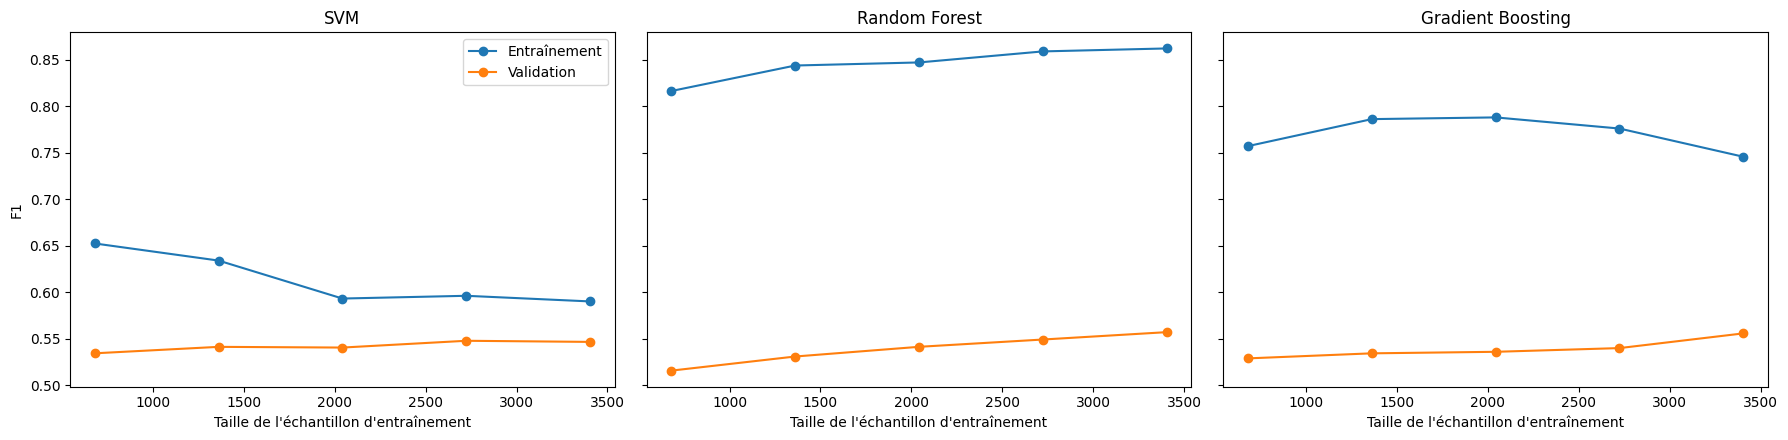

In [37]:
from sklearn.model_selection import learning_curve
import numpy as np
import matplotlib.pyplot as plt

compare = ["SVM", "Random Forest", "Gradient Boosting"]
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)

for ax, name in zip(axes, compare):
    sizes, tr, va = learning_curve(best_models[name], X_train, y_train, cv=cv,
                                   scoring="f1", n_jobs=-1,
                                   train_sizes=np.linspace(0.2, 1.0, 5))
    ax.plot(sizes, tr.mean(axis=1), "o-", label="Entraînement")
    ax.plot(sizes, va.mean(axis=1), "o-", label="Validation")
    ax.set_title(name)
    ax.set_xlabel("Taille de l'échantillon d'entraînement")
axes[0].set_ylabel("F1")
axes[0].legend()
plt.tight_layout()
plt.show()

**Lecture des courbes d'apprentissage.**
- **SVM** : les courbes d'entraînement et de validation se rapprochent (écart d'environ 0,04 avec tout l'échantillon) et la validation est quasi stable vers 0,55 : variance faible, mais le modèle plafonne, ce qui indique un biais résiduel ou un bruit irréductible dans les données.
- **Random Forest** : le F1 d'entraînement reste très élevé (≈ 0,86) alors que celui de validation est proche de 0,56 : écart d'environ 0,30, signe d'une **variance forte** (surapprentissage). La validation augmente encore avec la taille de l'échantillon.
- **Gradient Boosting** : situation intermédiaire (écart d'environ 0,19), avec une validation qui progresse encore légèrement.

Les trois courbes de validation convergent vers un F1 d'environ 0,55 : avec 4256 observations d'entraînement, aucun modèle ne se détache nettement. Les modèles d'ensemble pourraient bénéficier de davantage de données, le SVM beaucoup moins.

In [38]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

rows = []
for name, model in best_models.items():
    y_pred = model.predict(X_test)
    y_score = model.decision_function(X_test) if hasattr(model, "decision_function") \
              else model.predict_proba(X_test)[:, 1]
    rows.append({"Modèle": name,
                 "Accuracy": accuracy_score(y_test, y_pred),
                 "Précision": precision_score(y_test, y_pred),
                 "Rappel": recall_score(y_test, y_pred),
                 "F1": f1_score(y_test, y_pred),
                 "AUC": roc_auc_score(y_test, y_score),
                 "F1 train": f1_score(y_train, model.predict(X_train))})
final = pd.DataFrame(rows).set_index("Modèle")
final["Écart train-test"] = final["F1 train"] - final["F1"]
display(final.round(3))

,Accuracy,Précision,Rappel,F1,AUC,F1 train,Écart train-test
Modèle,,,,,,,
Régression logistique,0.735,0.400,0.797,0.533,0.817,0.541,0.007
k-NN,0.846,0.628,0.460,0.531,0.824,1.000,0.469
Arbre de décision,0.709,0.366,0.733,0.488,0.784,0.525,0.037
Naive Bayes,0.741,0.381,0.584,0.461,0.761,0.498,0.037
SVM,0.737,0.405,0.827,0.544,0.854,0.585,0.041
Random Forest,0.836,0.561,0.634,0.595,0.872,0.863,0.268
Gradient Boosting,0.795,0.476,0.777,0.590,0.867,0.711,0.121


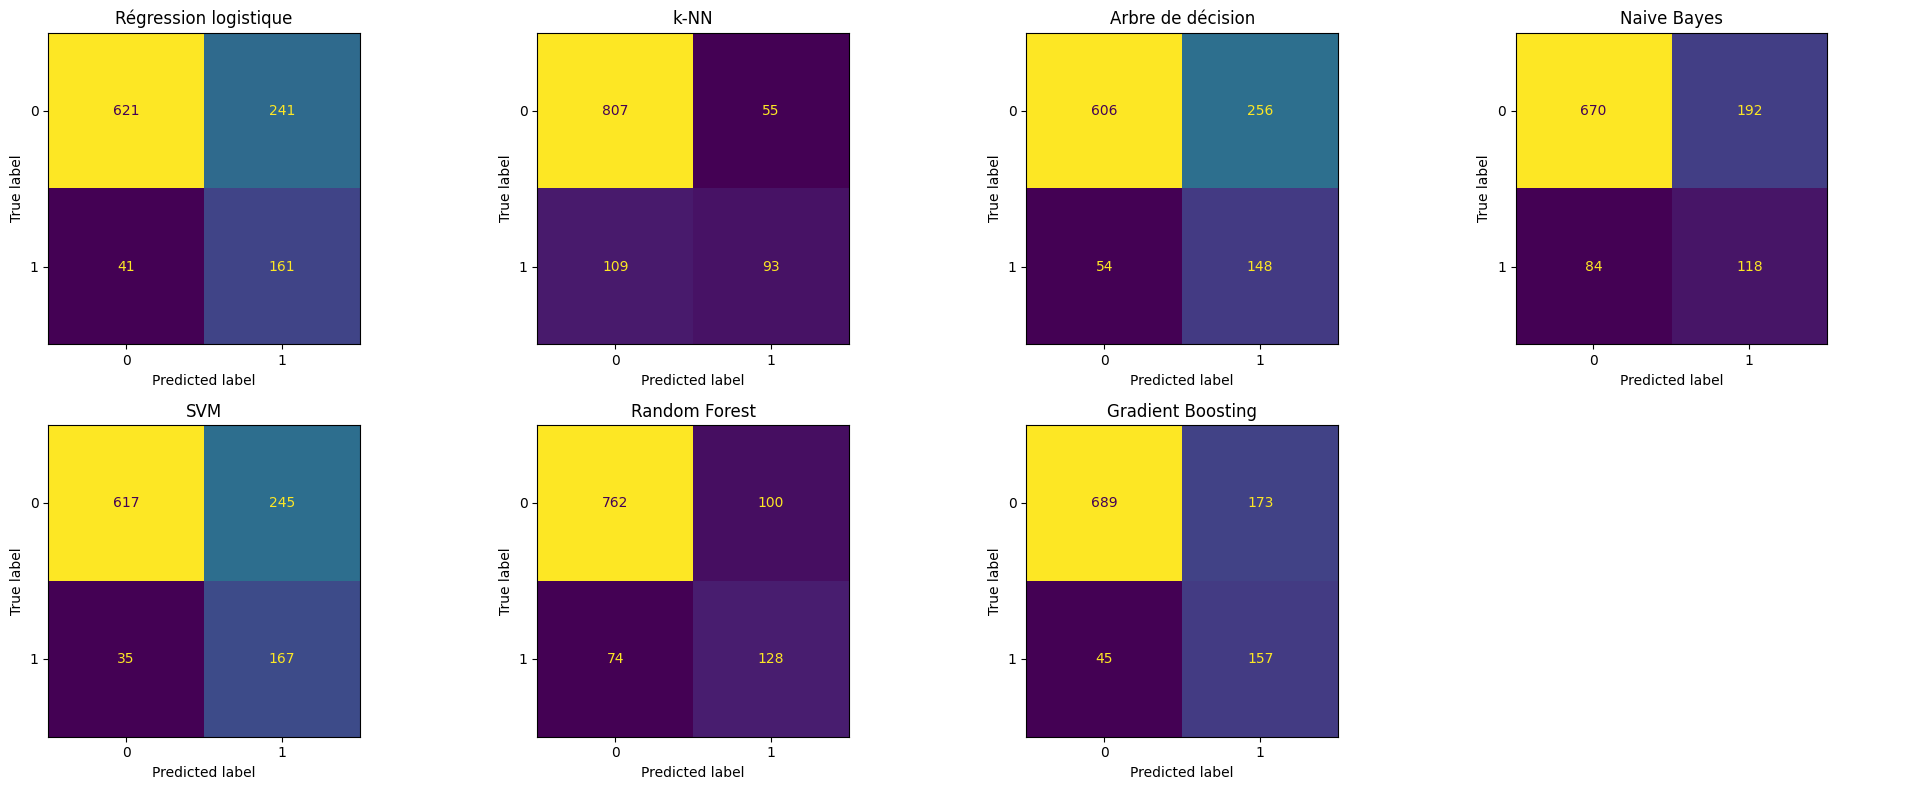

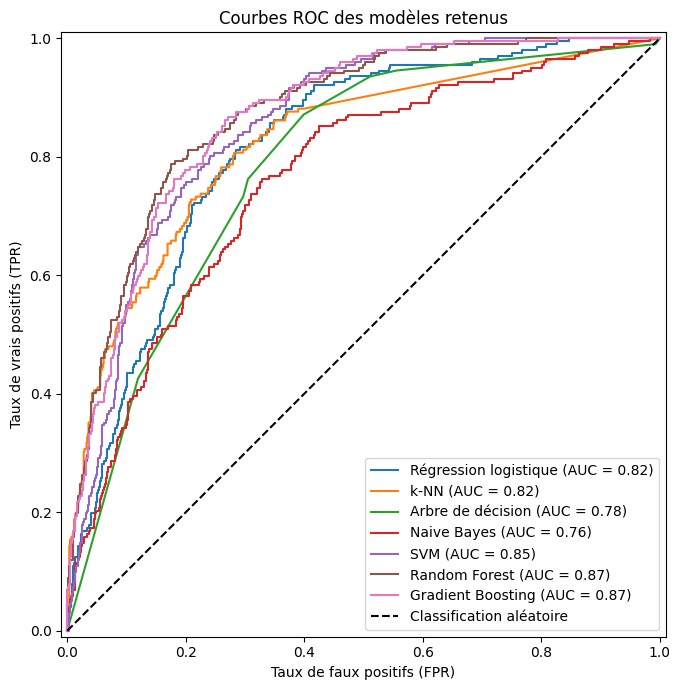

In [39]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay
import matplotlib.pyplot as plt

n = len(best_models)
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
axes = axes.ravel()

for ax, (name, model) in zip(axes, best_models.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, model.predict(X_test), ax=ax, colorbar=False)
    ax.set_title(name)

# cache la case vide (7 modèles pour 8 cases)
for ax in axes[n:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 7))
for name, model in best_models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Classification aléatoire")
ax.set_title("Courbes ROC des modèles retenus")
ax.set_xlabel("Taux de faux positifs (FPR)")
ax.set_ylabel("Taux de vrais positifs (TPR)")
ax.legend()
plt.tight_layout()
plt.show()

### 15. Interprétation des modèles
**Régression logistique.** Les variables étant standardisées, $w_j$ mesure la variation du log-odds associée à une augmentation d'un écart-type de $x_j$ ; $e^{w_j}$ est le rapport de cotes correspondant. La multicolinéarité (`alcohol`/`density`) impose une lecture prudente.
**Arbre de décision.** L'importance d'une variable est la réduction totale d'impureté qu'elle induit, normalisée. L'arbre représenté expose les règles ; les seuils sont exprimés en unités standardisées.
**Limite.** Ces mesures décrivent des associations prédictives, pas des relations causales.
**Random Forest.** L'importance est la réduction moyenne d'impureté sur l'ensemble des arbres. Elle favorise les variables continues à nombreuses valeurs distinctes ; elle sert à repérer les variables dominantes, pas à mesurer un effet.

In [40]:
from sklearn.model_selection import cross_validate

rows = []
for name, model in best_models.items():
    res = cross_validate(model, X_train, y_train, cv=cv,
                         scoring=["f1", "recall", "precision", "roc_auc"])
    rows.append({"Modèle": name,
                 "F1 (moy ± std)": f"{res['test_f1'].mean():.3f} ± {res['test_f1'].std():.3f}",
                 "Rappel": f"{res['test_recall'].mean():.3f} ± {res['test_recall'].std():.3f}",
                 "Précision": f"{res['test_precision'].mean():.3f} ± {res['test_precision'].std():.3f}",
                 "AUC": f"{res['test_roc_auc'].mean():.3f} ± {res['test_roc_auc'].std():.3f}"})
display(pd.DataFrame(rows).set_index("Modèle"))

,F1 (moy ± std),Rappel,Précision,AUC
Modèle,,,,
Régression logistique,0.539 ± 0.020,0.796 ± 0.032,0.408 ± 0.016,0.828 ± 0.013
k-NN,0.492 ± 0.023,0.436 ± 0.027,0.566 ± 0.032,0.794 ± 0.022
Arbre de décision,0.515 ± 0.018,0.765 ± 0.030,0.389 ± 0.013,0.797 ± 0.015
Naive Bayes,0.500 ± 0.011,0.633 ± 0.019,0.413 ± 0.012,0.769 ± 0.010
SVM,0.546 ± 0.011,0.799 ± 0.019,0.415 ± 0.009,0.843 ± 0.007
Random Forest,0.562 ± 0.025,0.592 ± 0.027,0.535 ± 0.031,0.848 ± 0.010
Gradient Boosting,0.551 ± 0.014,0.718 ± 0.030,0.447 ± 0.012,0.841 ± 0.010


In [41]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score

rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42)
names = ["SVM", "Random Forest", "Gradient Boosting"]
scores = {n: cross_val_score(best_models[n], X_train, y_train,
                             cv=rcv, scoring="f1", n_jobs=-1) for n in names}

for n in names:
    print(f"{n:20s} F1 = {scores[n].mean():.3f} ± {scores[n].std():.3f}")

for a, b in [("Random Forest", "Gradient Boosting"), ("Random Forest", "SVM"), ("Gradient Boosting", "SVM")]:
    d = scores[a] - scores[b]
    print(f"{a} − {b} : écart moyen {d.mean():+.3f}, {a} meilleur dans {(d > 0).mean():.0%} des plis")

SVM                  F1 = 0.546 ± 0.014
Random Forest        F1 = 0.555 ± 0.026
Gradient Boosting    F1 = 0.550 ± 0.018
Random Forest − Gradient Boosting : écart moyen +0.005, Random Forest meilleur dans 52% des plis
Random Forest − SVM : écart moyen +0.009, Random Forest meilleur dans 68% des plis
Gradient Boosting − SVM : écart moyen +0.004, Gradient Boosting meilleur dans 60% des plis


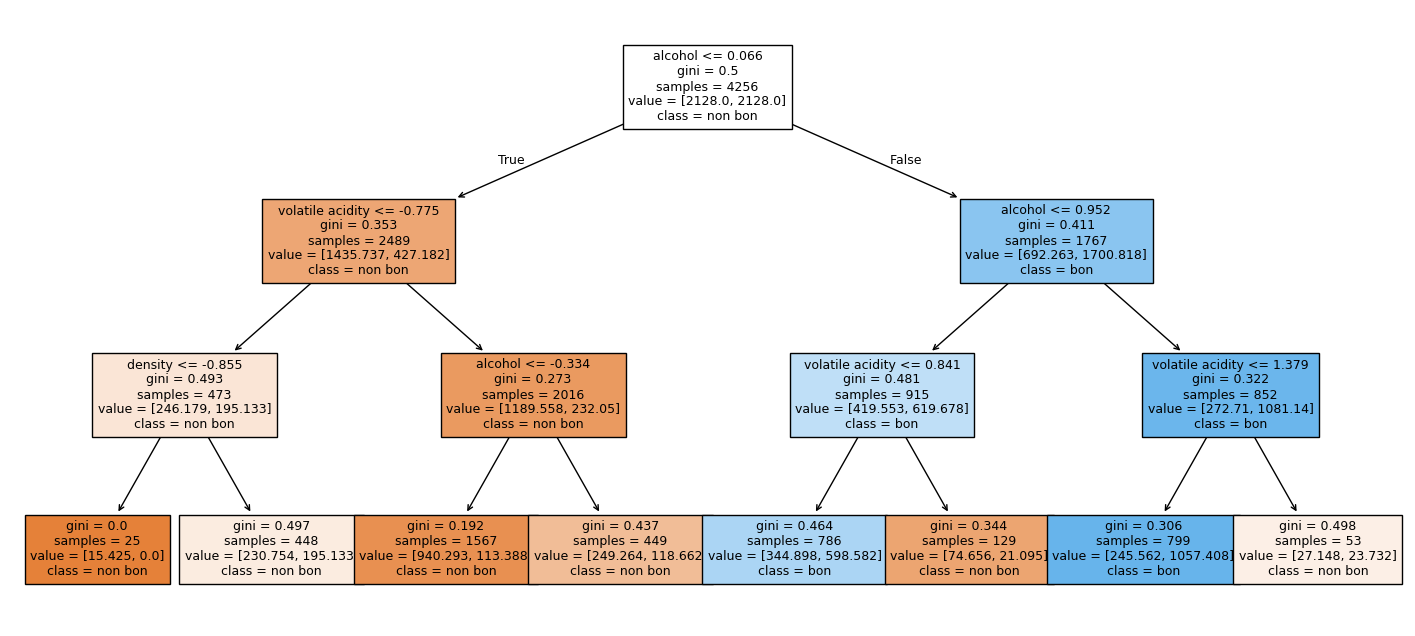

In [42]:
from sklearn.tree import plot_tree
tree = best_models["Arbre de décision"]
names = X_train.columns[tree.named_steps["select"].get_support()]
plt.figure(figsize=(18, 8))
plot_tree(tree.named_steps["clf"], feature_names=names,
          class_names=["non bon", "bon"], filled=True, max_depth=3, fontsize=9)
plt.show()

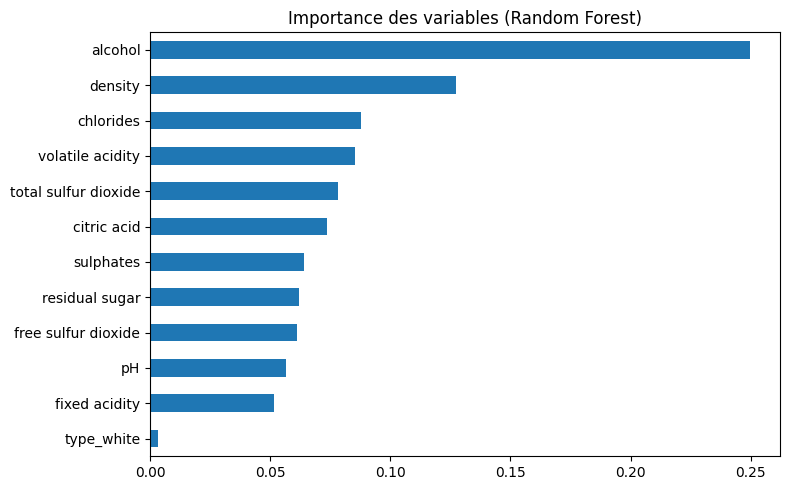

In [47]:
rf = best_models["Random Forest"]
selected_rf = X_train.columns[rf.named_steps["select"].get_support()]
imp_rf = pd.Series(rf.named_steps["clf"].feature_importances_, index=selected_rf).sort_values()
imp_rf.plot(kind="barh", figsize=(8, 5))
plt.title("Importance des variables (Random Forest)")
plt.tight_layout()
plt.show()

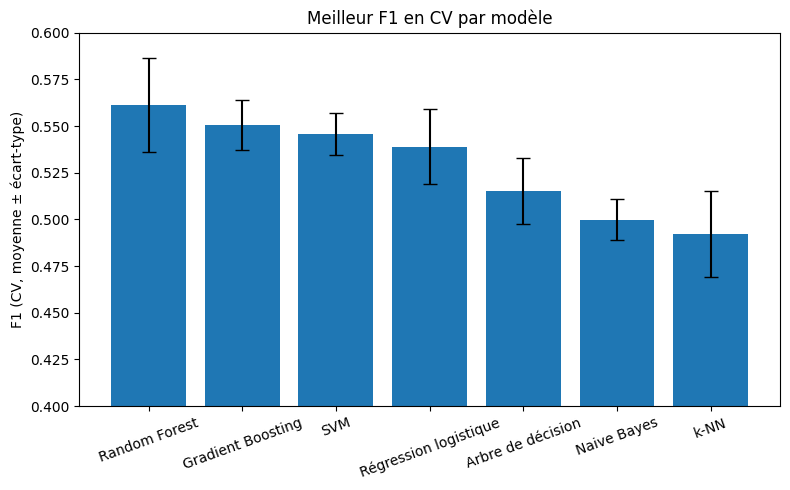

In [43]:
best_cv = cv_table.sort_values("F1 CV (moy)", ascending=False).drop_duplicates("Modèle")
plt.figure(figsize=(8, 5))
plt.bar(best_cv["Modèle"], best_cv["F1 CV (moy)"], yerr=best_cv["F1 CV (écart-type)"], capsize=5)
plt.ylim(0.4, 0.6)
plt.ylabel("F1 (CV, moyenne ± écart-type)")
plt.title("Meilleur F1 en CV par modèle")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

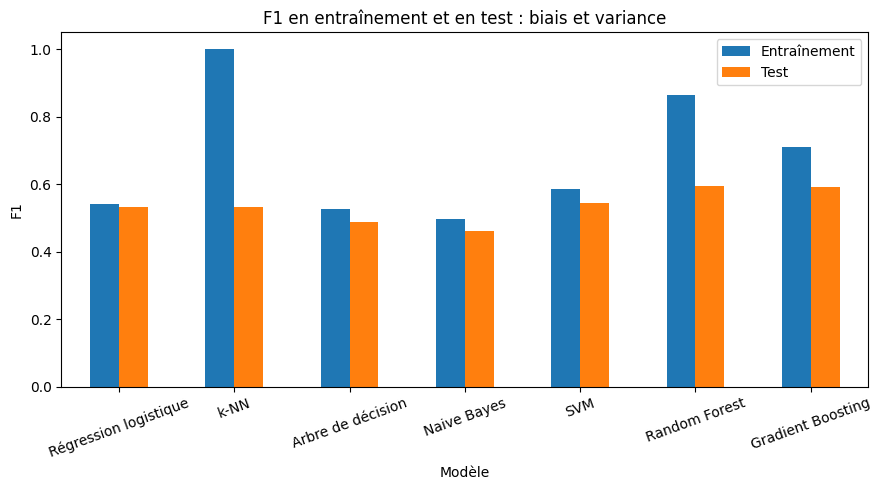

In [44]:
final[["F1 train", "F1"]].plot(kind="bar", figsize=(9, 5))
plt.title("F1 en entraînement et en test : biais et variance")
plt.ylabel("F1")
plt.xticks(rotation=20)
plt.legend(["Entraînement", "Test"])
plt.tight_layout()
plt.show()

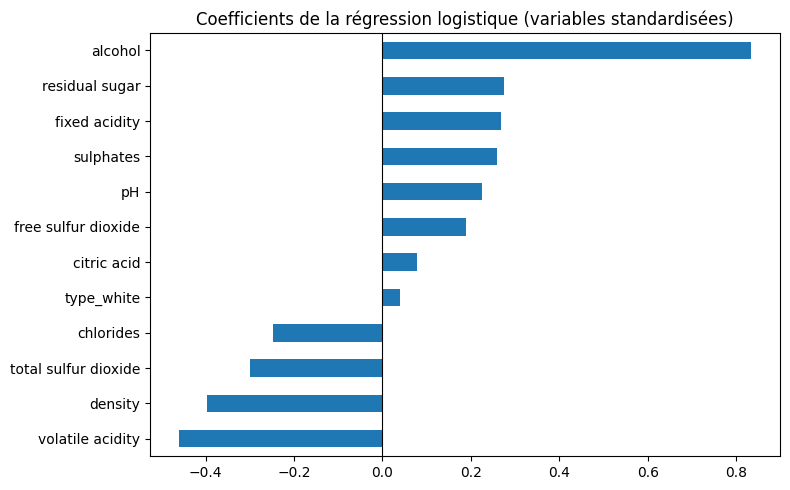

In [45]:
lr = best_models["Régression logistique"]
selected = X_train.columns[lr.named_steps["select"].get_support()]
coefs = pd.Series(lr.named_steps["clf"].coef_[0], index=selected).sort_values()
coefs.plot(kind="barh", figsize=(8, 5))
plt.title("Coefficients de la régression logistique (variables standardisées)")
plt.axvline(0, color="k", linewidth=0.8)
plt.tight_layout()
plt.show()